In [86]:
import numpy as np
import tensorflow as tf
from keras.datasets.cifar10 import load_data
from tensorflow.keras import layers, models, mixed_precision

tf.keras.backend.set_floatx('float32')

from matplotlib import pyplot as plt

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9607843..0.99215686].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.84313726..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.96862745..0.8352941].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.99215686].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9764706].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.94509804..0.9529412].
Clipping i

(50000, 32, 32, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9137255..0.70980394].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8117647..0.019607844].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.99215686].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9843137..0.96862745].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9137255].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9607843..1.0].
Cli

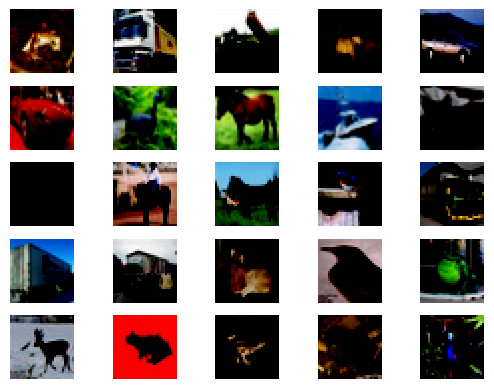

In [87]:
(x_train, y_train), (x_test, y_test) = load_data()
x_train = (x_train.astype("float32") - 127.5) / 127.5
print(x_train.shape)

# plot 25 images
for i in range(25):
	plt.subplot(5, 5, 1 + i)
	plt.axis('off')
	plt.imshow(x_train[i])
# plt.show()

In [88]:
IMAGE_SIZE = (32,32)
BATCH_SIZE = 256
EPOCHS = 100
TIMESTEPS = 1000
LEARNING_RATE = 1e-4
IS_TRAINING = False
FILE_NAME = "diffusion_unet_weights.weights.h5"

$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 + \alpha_t} \epsilon$$

$$noisy \space image = \sqrt{\bar{\alpha}_t} \times image + \sqrt{1- \bar{\alpha}_t} \times noise$$

In [89]:
# create a fixed linear beta schedule
beta_start = 0.0001
beta_end = 0.02
beta = np.linspace(beta_start, beta_end, TIMESTEPS, dtype=np.float32)

alpha = 1 - beta
alpha_bar = np.cumprod(alpha, axis=0)
alpha_bar = np.concatenate((np.array([1.], dtype=np.float32), alpha_bar[:-1]), axis=0)
sqrt_alpha_bar = np.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = np.sqrt(1-alpha_bar)

# this function will help us set the RNG key for Numpy
def set_key(key):
    np.random.seed(key)

# this function will add noise to the input as per the given timestamp
def forward_noise(key, x_0, t):
    set_key(key)
    noise = np.random.normal(size=x_0.shape)
    reshaped_sqrt_alpha_bar_t = np.reshape(np.take(sqrt_alpha_bar, t), (-1, 1, 1, 1))
    reshaped_sqrt_one_minus_alpha_bar_t = np.reshape(np.take(sqrt_one_minus_alpha_bar, t), (-1, 1, 1, 1))

    # Applying the actual formula
    noisy_image = reshaped_sqrt_alpha_bar_t  * x_0 + reshaped_sqrt_one_minus_alpha_bar_t  * noise
    return noisy_image, noise

# this function will be used to create sample timestamps between 0 &amp; T
def generate_timestamp(key, num):
    set_key(key)
    return tf.random.uniform(shape=[num], minval=0, maxval=TIMESTEPS, dtype=tf.int32)

def demo():
    fig = plt.figure(figsize=(15, 5)) # Adjusted figure size for better view
    sample_img = x_train[0] # Shape (32, 32, 3)
    sample_batch = np.expand_dims(sample_img, 0)
    timesteps_to_show = [0, 100, 200, 300, 400, 500] # Showing 0 to see original

    for index, i in enumerate(timesteps_to_show):
        noisy_im, noise = forward_noise(0, sample_batch, np.array([i,]))

        image_to_show = np.squeeze(noisy_im, 0)
        image_to_show = (image_to_show + 1) / 2.0

        image_to_show = np.clip(image_to_show, 0, 1)

        plt.subplot(1, len(timesteps_to_show), index+1)
        plt.title(f"Timestep: {i}")

        plt.imshow(image_to_show)
        plt.axis('off')

    plt.show()

# demo()


In [90]:
def sinusoidal_embedding(x, embedding_dim=256):
    """Creates sinusoidal embeddings for timesteps."""
    frequencies = tf.exp(
        tf.linspace(
            tf.math.log(1.0),
            tf.math.log(10000.0),
            embedding_dim // 2
        )
    )
    angular_speeds = 2.0 * np.pi * frequencies
    embeddings = tf.concat(
        [tf.sin(angular_speeds * x), tf.cos(angular_speeds * x)], axis=-1
    )
    return embeddings

def ResidualBlock(width):
    def apply(x):
        input_width = x.shape[3]
        if input_width == width:
            residual = x
        else:
            residual = layers.Conv2D(width, kernel_size=1)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("swish")(x)
        x = layers.Conv2D(width, kernel_size=3, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("swish")(x)
        x = layers.Conv2D(width, kernel_size=3, padding="same")(x)
        return layers.Add()([x, residual])
    return apply

def DownBlock(width, block_depth):
    def apply(x):
        x, skips = x
        for _ in range(block_depth):
            x = ResidualBlock(width)(x)
            skips.append(x)
        x = layers.AveragePooling2D(pool_size=2)(x)
        return x, skips
    return apply

def UpBlock(width, block_depth):
    def apply(x):
        x, skips = x
        x = layers.UpSampling2D(size=2, interpolation="bilinear")(x)
        for _ in range(block_depth):
            x = layers.Concatenate()([x, skips.pop()])
            x = ResidualBlock(width)(x)
        return x, skips
    return apply

def build_unet(img_size, img_channels):
    noisy_images = layers.Input(shape=(img_size, img_size, img_channels))
    t = layers.Input(shape=(1,))

    # 1. Time Embedding
    # We broadcast the time embedding to match the spatial dimensions of the image later
    t_emb = layers.Lambda(lambda x: sinusoidal_embedding(x, 32))(t)
    t_emb = layers.Dense(128, activation="swish")(t_emb)
    t_emb = layers.Dense(128)(t_emb)

    # 2. Initial Conv
    x = layers.Conv2D(32, kernel_size=1)(noisy_images)

    # 3. Downsampling
    skips = []
    x, skips = DownBlock(32, 2)((x, skips))
    x, skips = DownBlock(64, 2)((x, skips))
    x, skips = DownBlock(96, 2)((x, skips))

    # 4. Bottleneck
    x = ResidualBlock(128)(x)
    x = ResidualBlock(128)(x)

    # 5. Upsampling
    x, skips = UpBlock(96, 2)((x, skips))
    x, skips = UpBlock(64, 2)((x, skips))
    x, skips = UpBlock(32, 2)((x, skips))

    # 6. Output Layer
    x = layers.Conv2D(img_channels, kernel_size=1, kernel_initializer="zeros")(x)

    # Note: In a real advanced implementation, you add the time embedding
    # to every residual block. Here we keep it simple or concatenation can be used.
    # To make this code functional and simple, we rely on the UNet capacity.
    # A standard improvement is adding `t_emb` to intermediate layers.

    return models.Model([noisy_images, t], x, name="unet")

model = build_unet(IMAGE_SIZE[0], 3)
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
loss_fn = tf.keras.losses.MeanSquaredError()


In [91]:
def sinusoidal_embedding(x, embedding_dim=256):
    """Creates sinusoidal embeddings for timesteps."""
    x = tf.cast(x, tf.float32)
    frequencies = tf.exp(
        tf.linspace(
            tf.math.log(1.0),
            tf.math.log(10000.0),
            embedding_dim // 2
        )
    )
    angular_speeds = 2.0 * np.pi * frequencies
    embeddings = tf.concat(
        [tf.sin(angular_speeds * x), tf.cos(angular_speeds * x)], axis=-1
    )
    return embeddings


class TimestampEmbeddingInjection(layers.Layer):
    """
    Layer to project timestamp embedding to match feature map channels
    and add it to the feature map. Used at EVERY layer.
    """
    def __init__(self, target_channels, **kwargs):
        super().__init__(**kwargs)
        self.target_channels = target_channels
        self.dense = layers.Dense(target_channels)
    
    def call(self, inputs):
        x, t_emb = inputs
        # Project timestamp embedding to match channels
        t_proj = self.dense(t_emb)
        # Reshape for broadcasting: (batch, 1, 1, channels)
        t_proj = tf.reshape(t_proj, (-1, 1, 1, self.target_channels))
        # Add to feature map (scale and shift style)
        return x + t_proj
    
    def get_config(self):
        config = super().get_config()
        config.update({"target_channels": self.target_channels})
        return config


class EfficientSelfAttention(layers.Layer):
    """
    Memory-efficient self-attention using reduced dimensions.
    Only used at lower resolutions to avoid OOM.
    """
    def __init__(self, channels, num_heads=4, key_dim=None, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.num_heads = num_heads
        self.key_dim = key_dim or max(channels // num_heads, 8)
        
    def build(self, input_shape):
        self.norm = layers.LayerNormalization()
        self.to_qkv = layers.Dense(self.key_dim * self.num_heads * 3)
        self.to_out = layers.Dense(self.channels)
        super().build(input_shape)
    
    def call(self, x):
        batch_size = tf.shape(x)[0]
        h = x.shape[1] or tf.shape(x)[1]
        w = x.shape[2] or tf.shape(x)[2]
        
        # Save residual
        residual = x
        
        # Normalize
        x = self.norm(x)
        
        # Reshape to (batch, h*w, channels)
        x = tf.reshape(x, (batch_size, -1, self.channels))
        
        # Compute Q, K, V
        qkv = self.to_qkv(x)
        qkv = tf.reshape(qkv, (batch_size, -1, 3, self.num_heads, self.key_dim))
        qkv = tf.transpose(qkv, [2, 0, 3, 1, 4])  # (3, batch, heads, seq, dim)
        q, k, v = qkv[0], qkv[1], qkv[2]
        
        # Scaled dot-product attention
        scale = tf.math.sqrt(tf.cast(self.key_dim, tf.float32))
        attn = tf.matmul(q, k, transpose_b=True) / scale
        attn = tf.nn.softmax(attn, axis=-1)
        
        # Apply attention to values
        out = tf.matmul(attn, v)
        
        # Reshape back
        out = tf.transpose(out, [0, 2, 1, 3])  # (batch, seq, heads, dim)
        out = tf.reshape(out, (batch_size, -1, self.num_heads * self.key_dim))
        out = self.to_out(out)
        
        # Reshape to spatial
        out = tf.reshape(out, (batch_size, h, w, self.channels))
        
        return residual + out
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "channels": self.channels,
            "num_heads": self.num_heads,
            "key_dim": self.key_dim
        })
        return config


def ResidualBlockWithTimestamp(width):
    """
    Residual block that incorporates timestamp embedding at each conv layer.
    """
    def apply(inputs):
        x, t_emb = inputs
        input_width = x.shape[-1]
        
        if input_width == width:
            residual = x
        else:
            residual = layers.Conv2D(width, kernel_size=1)(x)
        
        # First conv block with timestamp injection
        x = layers.GroupNormalization(groups=min(8, width))(x)
        x = layers.Activation("swish")(x)
        x = layers.Conv2D(width, kernel_size=3, padding="same")(x)
        x = TimestampEmbeddingInjection(width)([x, t_emb])  # Inject timestamp
        
        # Second conv block with timestamp injection
        x = layers.GroupNormalization(groups=min(8, width))(x)
        x = layers.Activation("swish")(x)
        x = layers.Conv2D(width, kernel_size=3, padding="same")(x)
        x = TimestampEmbeddingInjection(width)([x, t_emb])  # Inject timestamp again
        
        return layers.Add()([x, residual])
    
    return apply


def DownBlockWithTimestamp(width, block_depth, use_attention=False):
    """
    Downsampling block with timestamp embedding at each layer.
    Attention is optional (only for lower resolutions).
    """
    def apply(inputs):
        x, t_emb, skips = inputs
        
        for i in range(block_depth):
            # Residual block with timestamp injection
            x = ResidualBlockWithTimestamp(width)([x, t_emb])
            
            # Attention only at lower resolutions
            if use_attention:
                x = EfficientSelfAttention(width, num_heads=4)(x)
            
            skips.append(x)
        
        # Downsample
        x = layers.AveragePooling2D(pool_size=2)(x)
        
        return x, t_emb, skips
    
    return apply


def UpBlockWithTimestamp(width, block_depth, use_attention=False):
    """
    Upsampling block with timestamp embedding at each layer.
    Attention is optional (only for lower resolutions).
    """
    def apply(inputs):
        x, t_emb, skips = inputs
        
        # Upsample
        x = layers.UpSampling2D(size=2, interpolation="bilinear")(x)
        
        for i in range(block_depth):
            # Concatenate with skip connection
            x = layers.Concatenate()([x, skips.pop()])
            
            # Residual block with timestamp injection
            x = ResidualBlockWithTimestamp(width)([x, t_emb])
            
            # Attention only at lower resolutions
            if use_attention:
                x = EfficientSelfAttention(width, num_heads=4)(x)
        
        return x, t_emb, skips
    
    return apply


def build_optimized_unet(img_size=32, img_channels=3, base_channels=32, t_emb_dim=128):
    """
    Build a memory-optimized U-Net with attention and timestamp embedding 
    at every layer of encoder and decoder.
    
    Key features:
    - Timestamp embedding injected in EVERY residual block
    - Attention only at 8x8 and 4x4 resolutions (to avoid OOM)
    - GroupNorm for stable training
    
    Args:
        img_size: Size of the input image (assumes square images)
        img_channels: Number of image channels (e.g., 3 for RGB)
        base_channels: Base number of channels
        t_emb_dim: Dimension of the timestamp embedding
    
    Returns:
        A Keras Model
    """
    # Inputs
    noisy_images = layers.Input(shape=(img_size, img_size, img_channels), name="noisy_images")
    t = layers.Input(shape=(1,), name="timestep")
    
    # ============ Timestamp Embedding Network ============
    # Create rich timestamp embedding that will be injected at every layer
    t_emb = layers.Lambda(lambda x: sinusoidal_embedding(x, t_emb_dim), name="sinusoidal_emb")(t)
    t_emb = layers.Dense(t_emb_dim * 4, activation="swish", name="t_dense1")(t_emb)
    t_emb = layers.Dense(t_emb_dim * 4, name="t_dense2")(t_emb)
    
    # ============ Initial Convolution ============
    x = layers.Conv2D(base_channels, kernel_size=3, padding="same", name="initial_conv")(noisy_images)
    
    # ============ Encoder (Downsampling) ============
    skips = []
    
    # Level 1: 32x32 -> 16x16 (NO attention - too large)
    x, _, skips = DownBlockWithTimestamp(
        base_channels, 
        block_depth=2, 
        use_attention=False  # No attention at 32x32
    )([x, t_emb, skips])
    
    # Level 2: 16x16 -> 8x8 (NO attention - still large)
    x, _, skips = DownBlockWithTimestamp(
        base_channels * 2, 
        block_depth=2, 
        use_attention=False  # No attention at 16x16
    )([x, t_emb, skips])
    
    # Level 3: 8x8 -> 4x4 (WITH attention - small enough)
    x, _, skips = DownBlockWithTimestamp(
        base_channels * 3, 
        block_depth=2, 
        use_attention=True  # Attention at 8x8
    )([x, t_emb, skips])
    
    # ============ Bottleneck (4x4 - WITH attention) ============
    x = ResidualBlockWithTimestamp(base_channels * 4)([x, t_emb])
    x = EfficientSelfAttention(base_channels * 4, num_heads=4)(x)
    x = ResidualBlockWithTimestamp(base_channels * 4)([x, t_emb])
    x = EfficientSelfAttention(base_channels * 4, num_heads=4)(x)
    
    # ============ Decoder (Upsampling) ============
    # Level 3: 4x4 -> 8x8 (WITH attention)
    x, _, skips = UpBlockWithTimestamp(
        base_channels * 3, 
        block_depth=2, 
        use_attention=True  # Attention at 8x8
    )([x, t_emb, skips])
    
    # Level 2: 8x8 -> 16x16 (NO attention)
    x, _, skips = UpBlockWithTimestamp(
        base_channels * 2, 
        block_depth=2, 
        use_attention=False  # No attention at 16x16
    )([x, t_emb, skips])
    
    # Level 1: 16x16 -> 32x32 (NO attention)
    x, _, skips = UpBlockWithTimestamp(
        base_channels, 
        block_depth=2, 
        use_attention=False  # No attention at 32x32
    )([x, t_emb, skips])
    
    # ============ Output Layer ============
    x = layers.GroupNormalization(groups=8)(x)
    x = layers.Activation("swish")(x)
    output = layers.Conv2D(
        img_channels, 
        kernel_size=3, 
        padding="same",
        kernel_initializer="zeros",
        name="output_conv"
    )(x)
    
    return models.Model([noisy_images, t], output, name="optimized_unet")


# ============ Usage Example =========== #
# Build the model
model = build_optimized_unet(
    img_size=32, 
    img_channels=3, 
    base_channels=32, 
    t_emb_dim=128
)
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
loss_fn = tf.keras.losses.MeanSquaredError()

In [92]:
@tf.function
def train_step(images):
    batch_size = tf.shape(images)[0]
    images = tf.cast(images, tf.float32)
    noise = tf.random.normal(tf.shape(images), dtype=tf.float32)

    # Generate random timesteps for each image in the batch
    t = tf.random.uniform((batch_size,), minval=0, maxval=TIMESTEPS, dtype=tf.int32)

    # Gather the correct alpha values for each timestep and reshape for broadcasting
    sqrt_alpha_prod_32 = tf.reshape(tf.gather(sqrt_alpha_bar, t), (-1, 1, 1, 1))
    sqrt_one_minus_alpha_prod_32 = tf.reshape(tf.gather(sqrt_one_minus_alpha_bar, t), (-1, 1, 1, 1))

    # Cast to float32
    sqrt_alpha_prod_32 = tf.cast(sqrt_alpha_prod_32, tf.float32)
    sqrt_one_minus_alpha_prod_32 = tf.cast(sqrt_one_minus_alpha_prod_32, tf.float32)

    noisy_images = sqrt_alpha_prod_32 * images + sqrt_one_minus_alpha_prod_32 * noise

    # Convert timestep to float and normalize for the model
    t_float = tf.cast(t, tf.float32) / tf.cast(TIMESTEPS, tf.float32)
    t_float = tf.reshape(t_float, (-1, 1))

    with tf.GradientTape() as tape:
        predicted_noise = model([noisy_images, t_float], training=True)
        loss = loss_fn(noise, predicted_noise)

    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

In [93]:
if IS_TRAINING:
    import time
    print("Starting Training...")
    # Create a proper batched dataset
    train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
    train_dataset = train_dataset.shuffle(buffer_size=10000).batch(BATCH_SIZE)

    for epoch in range(EPOCHS):
        start_time = time.time()
        epoch_loss = 0
        steps = 0
        for batch_images in train_dataset:
            loss = train_step(batch_images)
            epoch_loss += loss
            steps += 1

        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {epoch_loss/steps:.4f}, time taken: {time.time()-start_time}")

In [94]:
if IS_TRAINING:
    model.save_weights("diffusion_unet-xl.weights.h5")
    print("Model weights saved to diffusion_unet-xl.weights.h5")
else:
    model.load_weights(FILE_NAME)
    print("Model weights loaded from", FILE_NAME)


ValueError: A total of 79 objects could not be loaded. Example error message for object <Conv2D name=initial_conv, built=True>:

The shape of the target variable and the shape of the target value in `variable.assign(value)` must match. variable.shape=(3, 3, 3, 32), Received: value.shape=(1, 1, 3, 32). Target variable: <Variable path=initial_conv/kernel, shape=(3, 3, 3, 32), dtype=float32, value=[[[[-0.00453761 -0.02474684  0.06116121  0.03150782  0.03526825
     0.05861062  0.08653542 -0.0891787  -0.10565931  0.03018494
    -0.13332357  0.13660954  0.02725585 -0.07317752 -0.04924385
     0.08847678  0.12636636  0.02570833 -0.08718595  0.03863281
     0.01764883 -0.05104367  0.04744941  0.12130909 -0.12167695
    -0.03568782 -0.05425483 -0.13419081  0.00876406  0.12960468
     0.1138074  -0.05056485]
   [-0.05249807 -0.09180902 -0.06276137  0.11992864  0.09052078
     0.12520154  0.00916293 -0.02022374 -0.03481633 -0.12536898
     0.06408185 -0.13568002 -0.0422257   0.06583858 -0.030515

  0%|          | 0/999 [00:00<?, ?it/s]

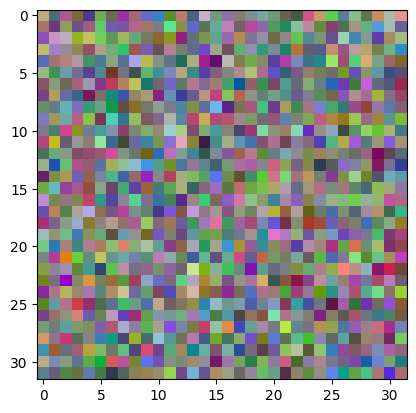

 10%|█         | 100/999 [00:12<01:44,  8.57it/s]

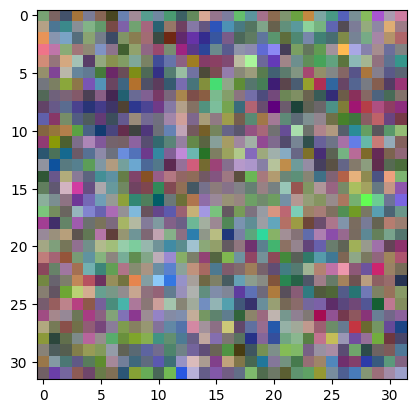

 20%|██        | 200/999 [00:23<01:28,  9.01it/s]

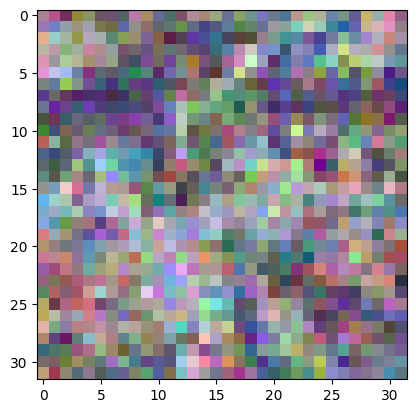

 30%|███       | 300/999 [00:35<01:22,  8.46it/s]

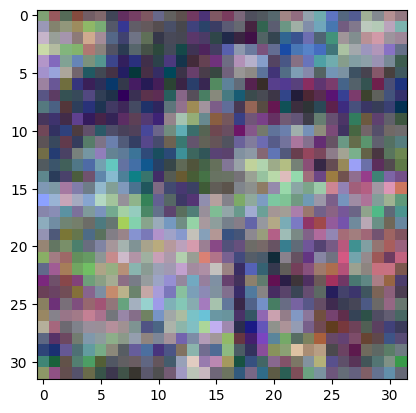

 40%|████      | 400/999 [00:46<01:05,  9.11it/s]

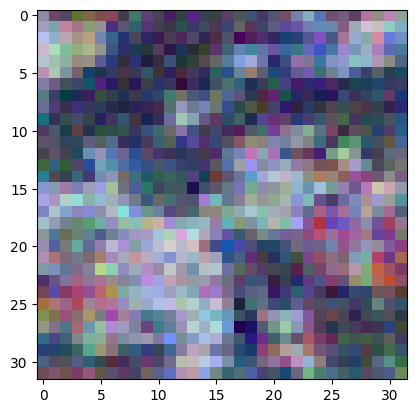

 50%|█████     | 500/999 [00:57<00:54,  9.12it/s]

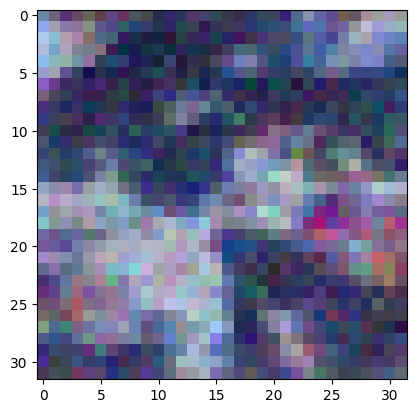

 60%|██████    | 600/999 [01:08<00:43,  9.12it/s]

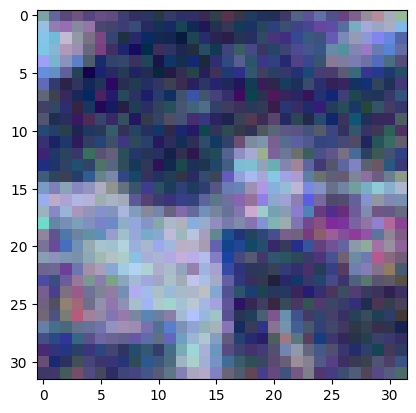

 70%|███████   | 700/999 [01:20<00:33,  9.01it/s]

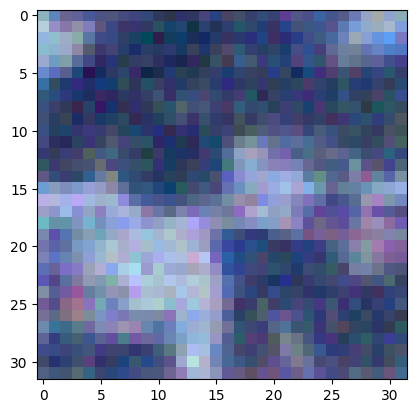

 80%|████████  | 800/999 [01:31<00:21,  9.13it/s]

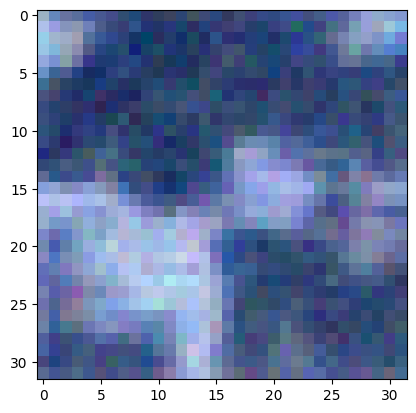

 90%|█████████ | 900/999 [01:42<00:11,  8.27it/s]

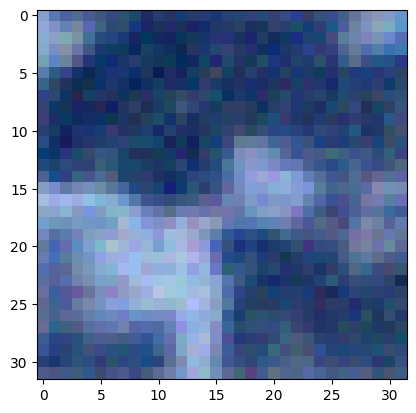

100%|██████████| 999/999 [01:54<00:00,  8.76it/s]


TypeError: Invalid shape (1, 32, 32, 3) for image data

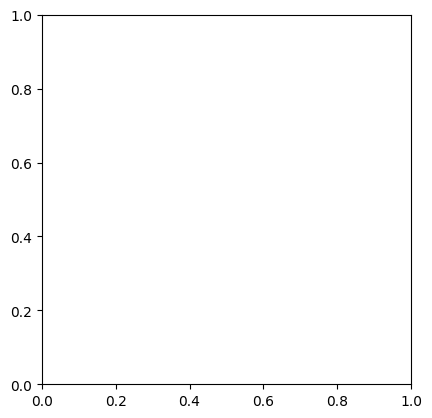

In [ ]:
import random
from tqdm import tqdm

def backward_denoising_ddpm(x_t, pred_noise, t):
    # ensure pred_noise matches x_t dtype (float32 in your current setup)
    pred_noise = tf.cast(pred_noise, x_t.dtype)

    alpha_t = tf.gather(alpha, t)
    alpha_t_bar = tf.gather(alpha_bar, t)

    eps_coef = (1 - alpha_t) / (1 - alpha_t_bar) ** 0.5
    mean = 1 / (alpha_t ** 0.5) * (x_t - eps_coef * pred_noise)

    var = tf.gather(beta, t)
    z = tf.random.normal(tf.shape(x_t), dtype=x_t.dtype)

    return mean + (var ** 0.5) * z


# Generating Gaussian noise
x = tf.random.normal((1, 32, 32, 3), dtype=tf.float32, seed=random.randint(0, 1000))

# Create a list to store output images
img_list_ddpm = []

# Append the initial noise to the list of images
img_list_ddpm.append(tf.squeeze(x, 0))

# Iterate over T timesteps
for i in tqdm(range(0, TIMESTEPS - 1)):
  # t-th timestep  
  t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
  
  # Predict noise using U-Net
  pred_noise = model([x, t])
  
  # Obtain the output from the noise using the formula seen before
  x = backward_denoising_ddpm(x, pred_noise, t)
  x_normalized = (tf.squeeze(x, 0) - tf.reduce_min(x)) / (tf.reduce_max(x) - tf.reduce_min(x))

  # Log the image after every 25 iterations
  if i % 100 == 0:
    img_list_ddpm.append(x_normalized)
    plt.imshow(x_normalized)
    plt.show()

# Display the final generated image
plt.imshow(x_normalized)
plt.show()
